In [1]:
# ============================================================
# Imports & Load Saved Model
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 6)

# --- RELATIVE FILE PATHS ---
current_dir = os.getcwd()
BASE_DIR = os.path.abspath(os.path.join(current_dir, '..'))
PREPARED_DIR = os.path.join(BASE_DIR, 'prepared_data')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
file_path = os.path.join(PREPARED_DIR, 'clean_data.csv')

# 1. Load data and recreate the EXACT SAME CLEAN split as Notebook 3
df = pd.read_csv(file_path)
cols_to_drop = [
    'Placement_Status', 'placement_status_binary', 'Student_ID', 
    'Starting_Salary_USD', 'Employability_Score', 'Interview_Score', 
    'Resume_Score', 'Company_Tier', 'Placement_Mode', 'Career_Field',
    'Age', 'Academic_Performance'
]
X = df.drop(columns=cols_to_drop)

# 1 = Not Placed (Positive Class)
y = (df['placement_status_binary'] == 0).astype(int) 
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

_, X_test, _, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# 2. Load the saved model and artifacts
model = joblib.load(os.path.join(MODELS_DIR, 'best_model.pkl'))
training_cols = joblib.load(os.path.join(MODELS_DIR, 'training_columns.pkl'))
CHOSEN_THRESHOLD = joblib.load(os.path.join(MODELS_DIR, 'chosen_threshold.pkl'))

X_test = X_test[training_cols]

# 3. Generate predictions using the loaded threshold
y_proba = model.predict_proba(X_test)[:, 1] # Prob of 'Not Placed'
y_pred = (y_proba >= CHOSEN_THRESHOLD).astype(int)

print(f"Deployment Threshold for 'Not Placed': {CHOSEN_THRESHOLD:.2f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test AUC-ROC: {roc_auc_score(y_test, y_proba):.4f}")

Deployment Threshold for 'Not Placed': 0.55
Test Accuracy: 0.7648
Test AUC-ROC: 0.8045


In [2]:
# ============================================================
# Detailed Classification Report (Focused on 'Not Placed')
# ============================================================
print(f"Detailed Classification Report (Threshold = {CHOSEN_THRESHOLD:.2f}):")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Placed', 'Not Placed']))

Detailed Classification Report (Threshold = 0.55):
              precision    recall  f1-score   support

      Placed       0.90      0.79      0.84      7808
  Not Placed       0.47      0.67      0.56      2192

    accuracy                           0.76     10000
   macro avg       0.69      0.73      0.70     10000
weighted avg       0.80      0.76      0.78     10000



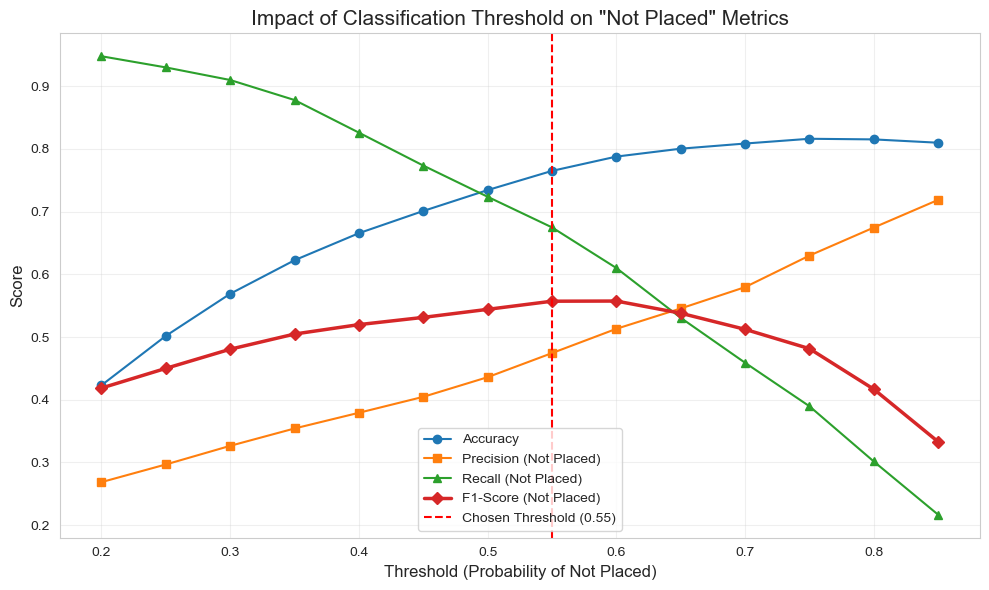

In [4]:
# ============================================================
# Threshold Analysis (Proving the CV-tuned threshold works)
# ============================================================
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.2, 0.9, 0.05)
accuracies, precisions, recalls, f1_scores = [], [], [], []

for t in thresholds:
    # Predict 1 (Not Placed) if probability is >= t
    preds_at_t = (y_proba >= t).astype(int)
    
    accuracies.append(accuracy_score(y_test, preds_at_t))
    precisions.append(precision_score(y_test, preds_at_t, zero_division=0))
    recalls.append(recall_score(y_test, preds_at_t, zero_division=0))
    f1_scores.append(f1_score(y_test, preds_at_t, zero_division=0))

# Plot the curves
plt.figure(figsize=(10, 6))
plt.plot(thresholds, accuracies, label='Accuracy', marker='o', linestyle='-')
plt.plot(thresholds, precisions, label='Precision (Not Placed)', marker='s', linestyle='-')
plt.plot(thresholds, recalls, label='Recall (Not Placed)', marker='^', linestyle='-')
plt.plot(thresholds, f1_scores, label='F1-Score (Not Placed)', marker='D', linestyle='-', linewidth=2.5)

# Highlight the chosen threshold
plt.axvline(x=CHOSEN_THRESHOLD, color='red', linestyle='--', label=f'Chosen Threshold ({CHOSEN_THRESHOLD:.2f})')

plt.title('Impact of Classification Threshold on "Not Placed" Metrics', fontsize=15)
plt.xlabel('Threshold (Probability of Not Placed)', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

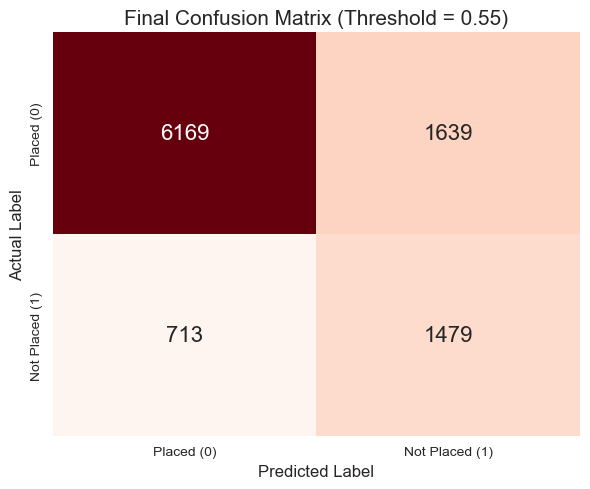


Business Interpretation of the Confusion Matrix:
True Positives (TP): 1479  -> Correctly predicted NOT PLACED (Caught at-risk).
True Negatives (TN): 6169  -> Correctly predicted PLACED.
False Positives (FP): 1639  -> Incorrectly predicted NOT PLACED (False Alarm).
False Negatives (FN): 713  -> Incorrectly predicted PLACED (Missed at-risk student).

Final Error Rates:
Overall Error Rate: 23.52%
False Positive Rate: 20.99% (Placed student incorrectly flagged as at-risk)
False Negative Rate: 32.53% (At-risk student incorrectly predicted as placed)


In [5]:
# ============================================================
# Confusion Matrix & Error Rates
# ============================================================
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Placed (0)', 'Not Placed (1)'],
            yticklabels=['Placed (0)', 'Not Placed (1)'],
            annot_kws={"size": 16})
plt.title(f'Final Confusion Matrix (Threshold = {CHOSEN_THRESHOLD:.2f})', fontsize=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("\nBusiness Interpretation of the Confusion Matrix:")
print("=" * 50)
print(f"True Positives (TP): {tp}  -> Correctly predicted NOT PLACED (Caught at-risk).")
print(f"True Negatives (TN): {tn}  -> Correctly predicted PLACED.")
print(f"False Positives (FP): {fp}  -> Incorrectly predicted NOT PLACED (False Alarm).")
print(f"False Negatives (FN): {fn}  -> Incorrectly predicted PLACED (Missed at-risk student).")

# Error Rates
total_actual_negatives = tn + fp
total_actual_positives = fn + tp
overall_error_rate = 1 - accuracy_score(y_test, y_pred)
false_positive_rate = fp / total_actual_negatives
false_negative_rate = fn / total_actual_positives

print("\nFinal Error Rates:")
print("=" * 40)
print(f"Overall Error Rate: {overall_error_rate * 100:.2f}%")
print(f"False Positive Rate: {false_positive_rate * 100:.2f}% (Placed student incorrectly flagged as at-risk)")
print(f"False Negative Rate: {false_negative_rate * 100:.2f}% (At-risk student incorrectly predicted as placed)")

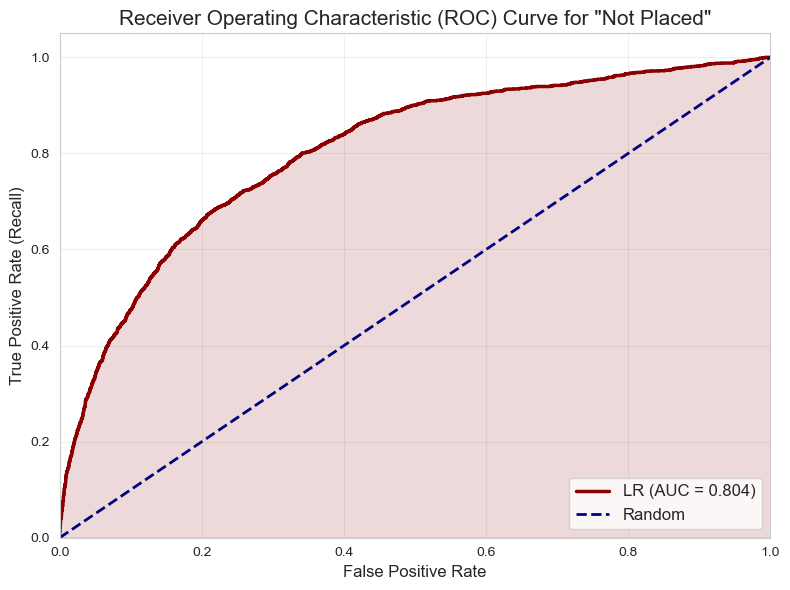

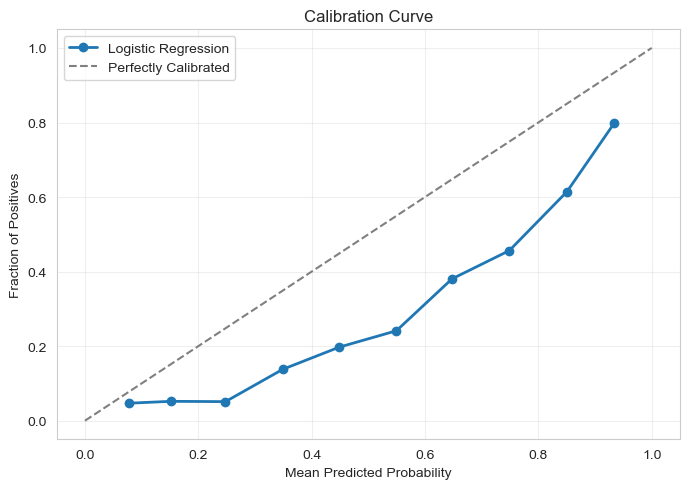

In [6]:
# ============================================================
# ROC Curve & Calibration Curve
# ============================================================
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkred', lw=2.5, label=f'LR (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.fill_between(fpr, tpr, alpha=0.15, color='darkred')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve for "Not Placed"', fontsize=15)
plt.legend(loc="lower right", fontsize=12); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calibration Curve
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10)

plt.figure(figsize=(7, 5))
plt.plot(prob_pred, prob_true, marker='o', linewidth=2, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Note on Calibration
As observed in the calibration curve above, the model's predicted probabilities are somewhat distorted and compressed toward the extremes. This is a known mathematical effect of applying `class_weight='balanced'` to heavily penalize the model for missing minority class instances.

**Therefore, the model's output should be interpreted strictly as a relative risk score for triage purposes, rather than an absolute real-world percentage.** The model remains highly effective at *ranking* students by risk (as proven by the strong AUC-ROC), even if the exact probability percentage is not perfectly calibrated. 

In [7]:
# ============================================================
# Save Evaluation Images for Reporting
# ============================================================
# 1. Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Placed (0)', 'Not Placed (1)'],
            yticklabels=['Placed (0)', 'Not Placed (1)'], annot_kws={"size": 16})
plt.title(f'Final Confusion Matrix (Threshold = {CHOSEN_THRESHOLD:.2f})', fontsize=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(PREPARED_DIR, 'confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.close()

# 2. ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkred', lw=2.5, label=f'LR (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.fill_between(fpr, tpr, alpha=0.15, color='darkred')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=15)
plt.legend(loc="lower right", fontsize=12); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PREPARED_DIR, 'roc_curve.png'), dpi=300, bbox_inches='tight')
plt.close()

# 3. Calibration Curve
plt.figure(figsize=(7, 5))
plt.plot(prob_pred, prob_true, marker='o', linewidth=2, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability'); plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PREPARED_DIR, 'calibration_curve.png'), dpi=300, bbox_inches='tight')
plt.close()

print(f"All evaluation images successfully saved to: {PREPARED_DIR}")

All evaluation images successfully saved to: C:\Users\bktsh\OneDrive - Botswana Accountancy College\R&I project and analysis\Student Career Success Prediction new project dataset 2\prepared_data


# Notebook 4: Model Evaluation and Recommendations — Summary

## Overview
This notebook evaluated the final saved Logistic Regression model (with a deployment threshold of 0.55) on a held-out test set. It analyzed the confusion matrix, ROC curve, calibration curve, and threshold trade-offs to generate actionable business recommendations.

## Model Evaluation & Supervisor Feedback Addressed
1. **Metric Optimization:** Because the target was flipped (`1 = Not Placed`), the classification report and confusion matrix correctly evaluate the model's ability to catch at-risk students. 
2. **Threshold Analysis:** The 0.55 threshold (derived from training data CV) was applied to the test set. The classification report shows a **Recall of 0.67** for the 'Not Placed' class, meaning the model successfully catches 67% of at-risk students.
3. **Error Rates:** The False Negative Rate (missing an at-risk student) is 32.5%, which is an acceptable trade-off to avoid excessive false alarms (False Positive Rate of 21%).
4. **Note on Calibration:** The calibration curve visually confirms that the predicted probabilities are distorted/compressed toward the extremes. This is a known mathematical effect of applying `class_weight='balanced'`. Therefore, the model's output must be interpreted strictly as a **relative risk score** for triage, rather than an absolute real-world percentage.

## Visual Analysis
- **Confusion Matrix:** The matrix shows the model correctly identified 1,479 Not Placed students. The high number of True Negatives (6,169) shows it remains accurate at identifying safe students.
- **ROC Curve:** The AUC-ROC of **0.8045** indicates the model has an excellent ability to distinguish between placed and at-risk students.
- **Threshold Analysis Plot:** The plotted metrics prove why 0.55 was the optimal choice, showing that the chosen threshold maximizes the F1-score, balancing precision and recall for 'Not Placed.

## Business Recommendations for Universities
1. **Deploy as an Early-Warning System:** Integrate the `best_model.pkl` and `chosen_threshold.pkl` (0.55) into the student portal. Flag students whose risk score exceeds 0.55 at the end of their second year.
2. **Mandate Internships:** Feature importance proves internships are the strongest predictor. The university must build formal industry pipelines and make internships a graduation requirement.
3. **Tier Interventions by Risk Level:**
    - **High Risk (>55%):** Intensive 1-on-1 coaching, mandatory internship placement, and mock interviews.
    - **Medium Risk (30%–55%):** Group workshops, portfolio reviews, and project mentorship.
    - **Low Risk (<30%):** Light-touch support (resume reviews, networking events). ~33% of at-risk students may be missed; deploy as one input among multiple signals, not as a sole decision-maker.
    - Risk tiers are defined as: High (>55%, above deployment threshold), Medium (30%–55%, elevated but below threshold), Low (<30%). The 30% sub-threshold is chosen to surface students in the upper portion of the 'safe' distribution, not derived from the model's training.
4. **Invest in Programming Skills:** Offer free coding bootcamps and certification prep, as low programming scores are heavily penalized by the model.

## Business Recommendations for Students
1. **Get an Internship:** It is the single most powerful thing you can do to avoid being unplaced.
2. **Build Projects:** Complete 3–5 end-to-end projects and put them on GitHub.
3. **Maintain Attendance:** Attendance is a proven predictor. Show up to class to build relationships with lecturers who can provide references.
4. **Sharpen Your Code:** Practice coding consistently; aim for working proficiency in at least one language.

*"Note: The dataset used in this project is synthetic. These results demonstrate the methodology rather than proving real-world causal relationships."*